# COMPAS Analysis — Follow-Along Notebook

This notebook reproduces the calculations in ProPublica's analysis of the COMPAS recidivism risk scores (["Machine Bias"](https://www.propublica.org/article/machine-bias-risk-assessments-in-criminal-sentencing/)), translated from R to Python. You may find it useful to keep [the methodology write-up](https://www.propublica.org/article/how-we-analyzed-the-compas-recidivism-algorithm/) open in another tab.

**How this notebook works**

* All of the code is written for you. Run each cell in order (Shift + Enter) and **read the output carefully**.
* ProPublica's original notebook states its conclusions after the analysis. Here those conclusions have been removed. When you reach a **✍️ Your turn** cell, use the output above it to write the conclusion yourself. Fill in the sentence frame, and give the actual numbers.
* At the end of each major section there is a **💭 Reflection** prompt. Write a thoughtful paragraph (4–8 sentences) that connects what you found to the article you read.
* Write your answers in the **Your answer** cells (double-click a cell to edit it, Shift + Enter to render it).

In [1]:
# If lifelines is not installed, uncomment the next line and run this cell once.
# %pip install lifelines

import math
import re
import statistics
import warnings
from csv import DictReader

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from lifelines import CoxPHFitter, KaplanMeierFitter

from truth_tables import PeekyReader, Person, table, is_race, count, vtable, hightable, vhightable

warnings.filterwarnings('ignore')
pd.set_option('display.width', 120)

### Helper functions

These helpers stand in for R functions used in the original analysis. You don't need to understand every line, but read the docstrings so you know what each one does.

In [2]:
def relative_risk(model, term):
    """Converts a logistic regression coefficient into an approximate relative risk.

    Logistic regression gives odds ratios. ProPublica converts them to "X times as likely"
    using the probability of a high score for the reference group (the intercept).

    Args:
        model: A fitted statsmodels logistic regression result with an 'Intercept' term.
        term: Name of the coefficient to convert, exactly as it appears in `model.params`.

    Returns:
        float: How many times as likely the group in `term` is to get a higher score than
        the reference group (e.g. 1.45 means 45% more likely).
    """
    intercept = model.params['Intercept']
    control = math.exp(intercept) / (1 + math.exp(intercept))
    odds_ratio = math.exp(model.params[term])
    return odds_ratio / (1 - control + control * odds_ratio)


def concordance(data, risk):
    """Computes the concordance (C-index) for counting-process survival data.

    For every pair where one person recidivated while the other was still at risk, asks:
    did the model give the person who recidivated the higher risk? Ties count as half.
    Matches the concordance reported by R's `coxph`.

    Args:
        data: DataFrame with one row per at-risk interval and columns 'start', 'end' and
            'event' (1 if the interval ended in recidivism, otherwise 0).
        risk: Predicted risk for each row of `data`, in the same order (e.g. the output of
            `CoxPHFitter.predict_partial_hazard`).

    Returns:
        float: Concordance between 0 and 1, where 0.5 is a coin flip and 1.0 is a perfect
        ranking.
    """
    s, e, d = (data[c].to_numpy() for c in ('start', 'end', 'event'))
    r = np.asarray(risk)
    agree = disagree = tied = 0
    for t in np.unique(e[d == 1]):
        died = (e == t) & (d == 1)
        at_risk = (s < t) & ((e > t) | ((e == t) & (d == 0)))
        rr = np.sort(r[at_risk])
        for ri in r[died]:
            lo, hi = np.searchsorted(rr, ri, 'left'), np.searchsorted(rr, ri, 'right')
            agree += lo
            disagree += len(rr) - hi
            tied += hi - lo
    return (agree + tied / 2) / (agree + disagree + tied)


def fit_cox(data, formula):
    """Fits a Cox proportional hazards model on counting-process data and prints a summary.

    Args:
        data: DataFrame with 'start', 'end' and 'event' columns plus every predictor named
            in `formula`.
        formula: Right-hand side of the model, e.g. 'score_factor' or
            'race_factor * score_factor'.

    Returns:
        CoxPHFitter: The fitted lifelines model.
    """
    cph = CoxPHFitter()
    predictors = [c for c in data.columns if c in re.findall(r'\w+', formula)]
    cph.fit(data[['start', 'end', 'event'] + predictors],
            duration_col='end', event_col='event', entry_col='start', formula=formula)
    print(f"n = {len(data)}, number of events = {int(data.event.sum())}\n")
    print(cph.summary[['coef', 'exp(coef)', 'se(coef)', 'p']].round(5).to_string())
    print(f"\nConcordance = {concordance(data, cph.predict_partial_hazard(data)):.3f}")
    return cph


def km_by_score(data, ax=None, title=''):
    """Plots Kaplan-Meier survival curves for each COMPAS score level.

    Each curve shows the share of people in that score group who have NOT yet recidivated.

    Args:
        data: DataFrame with 'start', 'end', 'event' and 'score_factor' columns.
        ax: Matplotlib axes to draw on. Defaults to the current axes.
        title: Title for the plot.

    Returns:
        matplotlib.axes.Axes: The axes containing the plot.
    """
    ax = ax or plt.gca()
    for level in ['Low', 'Medium', 'High']:
        sub = data[data.score_factor == level]
        KaplanMeierFitter().fit(sub.end, sub.event, entry=sub.start, label=level).plot_survival_function(ax=ax)
    ax.set_ylim(0, 1)
    ax.set_title(title)
    ax.set_xlabel('Days')
    ax.set_ylabel('Share not yet recidivated')
    return ax


def survival_at(data, days=730):
    """Estimates the share of each score group that has NOT recidivated after a given time.

    Args:
        data: DataFrame with 'start', 'end', 'event' and 'score_factor' columns.
        days: Number of days of follow-up. Defaults to 730 (two years).

    Returns:
        pd.Series: Kaplan-Meier survival estimate for the Low, Medium and High groups.
    """
    rows = {}
    for level in ['Low', 'Medium', 'High']:
        sub = data[data.score_factor == level]
        kmf = KaplanMeierFitter().fit(sub.end, sub.event, entry=sub.start)
        rows[level] = round(float(kmf.survival_function_at_times(days).iloc[0]), 3)
    return pd.Series(rows, name=f'survival at {days} days')


def error_rates(recid, surv, prefix=''):
    """Computes false positive and false negative rates, using the rules in truth_tables.table.

    Args:
        recid: List of `Person` objects who recidivated within two years.
        surv: List of `Person` objects who did not recidivate within two years.
        prefix: '' for the general recidivism score or 'v' for the violent score.

    Returns:
        tuple[float, float]: The false positive rate and false negative rate, in percent.
    """
    fp = count(lambda i: getattr(i, prefix + 'high'), surv)
    fn = count(lambda i: getattr(i, prefix + 'low'), recid)
    return fp / len(surv) * 100, fn / len(recid) * 100

## Loading the Data

We select fields for severity of charge, number of priors, demographics, age, sex, COMPAS scores, and whether each person was accused of a crime within two years.

In [3]:
raw_data = pd.read_csv('./compas-scores-two-years.csv')
len(raw_data)

7214

However, not all of the rows are usable for the first round of analysis. ProPublica removed rows for several reasons:

* If the charge date of a defendant's COMPAS-scored crime was not within 30 days of when the person was arrested, we assume that, because of data quality issues, we do not have the right offense.
* The recidivist flag `is_recid` was coded as -1 if no COMPAS case could be found at all.
* Ordinary traffic offenses (`c_charge_degree` of `'O'`) will not result in jail time, so they are removed (there are only two).
* The underlying Broward County data was filtered to include only people who either recidivated within two years or had at least two years outside of a correctional facility.

In [4]:
columns = ['age', 'c_charge_degree', 'race', 'age_cat', 'score_text', 'sex', 'priors_count',
           'days_b_screening_arrest', 'decile_score', 'is_recid', 'two_year_recid', 'c_jail_in', 'c_jail_out']

df = raw_data[columns]
df = df[(df.days_b_screening_arrest <= 30) &
        (df.days_b_screening_arrest >= -30) &
        (df.is_recid != -1) &
        (df.c_charge_degree != 'O') &
        (df.score_text != 'N/A')].copy()
len(df)

6172

How does a defendant's COMPAS decile score relate to how long they stayed in jail?

In [5]:
df['length_of_stay'] = (pd.to_datetime(df.c_jail_out).dt.normalize() -
                        pd.to_datetime(df.c_jail_in).dt.normalize()).dt.days
df.length_of_stay.corr(df.decile_score)

np.float64(0.20732969161470466)

### ✍️ Your turn — Question 1

Interpret the correlation coefficient above.

> Higher COMPAS scores are **(strongly / slightly / not)** correlated with a **(longer / shorter)** length of stay (r = ____).

*Hint:* a correlation of 1 is a perfect positive relationship and 0 is no relationship. Where does this value fall?

**Your answer (Q1):**

Higher COMPAS scores are **slightly** correlated with a **longer** length of stay (**r = 0.2073**). This is a weak positive relationship, much closer to 0 than to 1. It does not establish that the score caused a longer jail stay.

After filtering, we have the following demographic breakdown:

In [6]:
df.age_cat.value_counts()

age_cat
25 - 45            3532
Less than 25       1347
Greater than 45    1293
Name: count, dtype: int64

In [7]:
race_counts = df.race.value_counts()
pd.DataFrame({'count': race_counts, 'percent': (race_counts / len(df) * 100).round(2)})

,count,percent
race,,
African-American,3175,51.44
Caucasian,2103,34.07
Hispanic,509,8.25
Other,343,5.56
Asian,31,0.50
Native American,11,0.18


In [8]:
df.score_text.value_counts()

score_text
Low       3421
Medium    1607
High      1144
Name: count, dtype: int64

In [9]:
pd.crosstab(df.sex, df.race)

race,African-American,Asian,Caucasian,Hispanic,Native American,Other
sex,,,,,,
Female,549,2,482,82,2,58
Male,2626,29,1621,427,9,285


In [10]:
sex_counts = df.sex.value_counts()
pd.DataFrame({'count': sex_counts, 'percent': (sex_counts / len(df) * 100).round(2)})

,count,percent
sex,,
Male,4997,80.96
Female,1175,19.04


In [11]:
n_recid = (df.two_year_recid == 1).sum()
print(f"Recidivated within two years: {n_recid} ({n_recid / len(df) * 100:.2f}%)")

Recidivated within two years: 2809 (45.51%)


Judges are often shown two kinds of COMPAS output: a category (Low, Medium or High risk) and a corresponding **decile score** from 1 (lowest risk) to 10 (highest risk). Let's compare the distribution of decile scores for Black and white defendants.

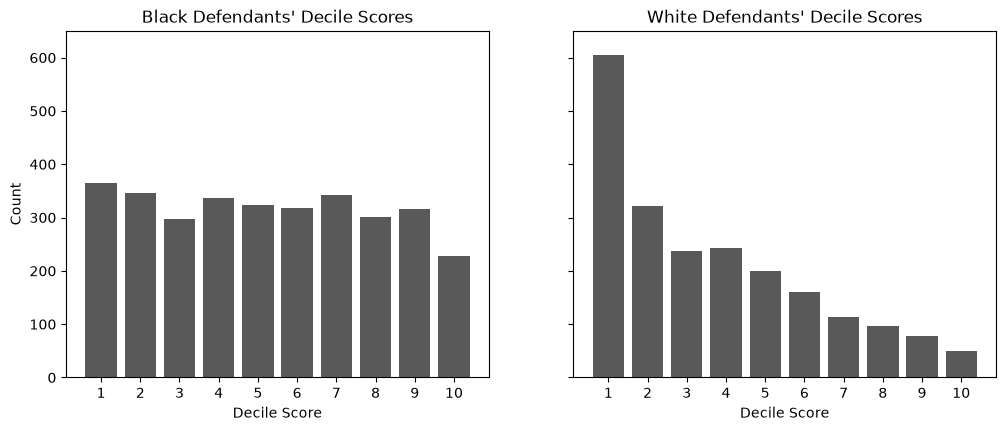

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, (race, label) in zip(axes, [('African-American', 'Black'), ('Caucasian', 'White')]):
    counts = df[df.race == race].decile_score.value_counts().sort_index()
    ax.bar(counts.index.astype(str), counts.values, color='0.35')
    ax.set_ylim(0, 650)
    ax.set_xlabel('Decile Score')
    ax.set_title(f"{label} Defendants' Decile Scores")
axes[0].set_ylabel('Count')
plt.show()

In [13]:
pd.crosstab(df.decile_score, df.race)

race,African-American,Asian,Caucasian,Hispanic,Native American,Other
decile_score,,,,,,
1,365,15,605,159,0,142
2,346,4,321,89,2,60
3,298,5,238,73,1,32
4,337,0,243,47,0,39
5,323,1,200,39,0,19
6,318,2,160,27,2,20
7,343,1,113,28,2,9
8,301,2,96,14,0,7
9,317,0,77,17,2,7


### ✍️ Your turn — Question 2

Compare the two histograms.

> For **white** defendants, the number of people at each decile score **(rises / falls / stays about the same)** as the score increases. For **Black** defendants, the scores are **(concentrated at the low end / spread fairly evenly / concentrated at the high end)**.

Then, in one sentence: why can't we conclude from these histograms alone that COMPAS is biased? (What else could explain the difference?)

**Your answer (Q2):**

For **white** defendants, the number of people generally **falls** as the decile score increases: there are **605** at score 1 and **50** at score 10. For **Black** defendants, scores are **spread fairly evenly**, with most deciles containing roughly 300–365 people, although score 10 is lower at 227. The histograms alone cannot establish bias because differences in age, prior records, charges, or recorded recidivism could also contribute to the different score distributions.

## 💭 Reflection 1: The data

Before running any models, ProPublica made several choices about which defendants to **keep** and which to **drop** (the 30-day window, missing cases, traffic offenses, two-year follow-up).

* Pick one of these filters. Who gets removed by it, and why might that matter for the conclusions?
* The article focuses on Broward County, Florida. What are the limits of generalizing from one county?
* The outcome we call "recidivism" is really "was *charged* with a new crime within two years." How might that differ from "committed a new crime," and could the difference vary by race?

**Your reflection (R1):**

The 30-day filter removes defendants whose COMPAS screening was more than 30 days before or after the recorded arrest. This helps avoid matching a score to the wrong offense, but it can also exclude people whose records are delayed or incomplete. If those record problems occur more often for one group, the remaining sample may not represent everyone equally. Broward County has its own population, policing practices, and court procedures, so I would not assume that the same results apply to every county or time period. A new charge measures contact with the justice system, not proof that someone committed a new crime. Differences in police surveillance, reporting, and charging decisions could therefore affect the measured outcome differently by race. These limits matter because the analysis evaluates predictions of recorded charges rather than an unbiased record of all harmful behavior.

## Racial Bias in COMPAS

Our first question is whether there is a significant difference in COMPAS scores between races. To answer it we run a **logistic regression**. The outcome is whether someone got a Medium/High score (vs. Low), and the predictors are race, sex, age, number of priors, charge degree (felony vs. misdemeanor), and whether the person actually reoffended within two years.

The **reference groups** (what everyone is compared against) are: white (`Caucasian`), male, age 25–45, and felony charge.

In [14]:
df['high_score'] = (df.score_text != 'Low').astype(int)

formula = ("high_score ~ C(sex, Treatment('Male')) + C(age_cat, Treatment('25 - 45'))"
           " + C(race, Treatment('Caucasian')) + priors_count"
           " + C(c_charge_degree, Treatment('F')) + two_year_recid")
model = smf.logit(formula, data=df).fit(disp=0)
print(model.summary())

                           Logit Regression Results                           
Dep. Variable:             high_score   No. Observations:                 6172
Model:                          Logit   Df Residuals:                     6160
Method:                           MLE   Df Model:                           11
Date:                Thu, 22 Oct 2026   Pseudo R-squ.:                  0.2729
Time:                        22:01:36   Log-Likelihood:                -3084.2
converged:                       True   LL-Null:                       -4241.7
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                                          coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------------------------
Intercept                                              -1.5255      0.079    -19.430      0.000      -1.679      -1.372
C(sex, T

Logistic regression coefficients are in "log-odds," which are hard to interpret directly. The `relative_risk` helper converts a coefficient into "how many times as likely to get a higher score, compared to the reference group."

In [15]:
black_rr = relative_risk(model, "C(race, Treatment('Caucasian'))[T.African-American]")
print(f"Black vs. white: {black_rr:.3f}")

Black vs. white: 1.453


### ✍️ Your turn — Question 3

Write the main finding of this regression.

> Black defendants are ____% **(more / less)** likely than white defendants to receive a higher score, correcting for the seriousness of their crime, ________________, and ________________.

*Hint:* a relative risk of 1.25 means "25% more likely." Look at the list of other predictors in the model to fill in what was "corrected for."

**Your answer (Q3):**

Black defendants are approximately **45.3% more likely** than white defendants to receive a Medium/High score, correcting for the seriousness of the charge, **prior criminal record**, and **recorded two-year recidivism**, as well as age category and sex. This follows from the displayed relative risk: **(1.453 − 1) × 100 = 45.3%**. The helper uses the reference-group intercept probability to convert the odds ratio, so this is a reference-profile relative-risk estimate rather than a population-average effect or a causal conclusion.

In [16]:
female_rr = relative_risk(model, "C(sex, Treatment('Male'))[T.Female]")
young_rr = relative_risk(model, "C(age_cat, Treatment('25 - 45'))[T.Less than 25]")
print(f"Women vs. men:            {female_rr:.3f}")
print(f"Under 25 vs. age 25-45:   {young_rr:.3f}")

Women vs. men:            1.195
Under 25 vs. age 25-45:   2.496


### ✍️ Your turn — Question 4

Now do the same for sex and age.

> Women are ____% **(more / less)** likely than men to get a higher score.
>
> People under 25 are ____ times as likely to get a higher score as middle-aged (25–45) defendants.

Which of these two results surprised you more, and why?

**Your answer (Q4):**

Women are approximately **19.5% more likely** than men to receive a higher score, based on **(1.195 − 1) × 100**. People under 25 are **2.496 times** as likely to receive a higher score as defendants aged 25–45. The result for women is more surprising to me because the later survival table shows lower recorded recidivism for women within each score category, yet the adjusted general-score model assigns women a higher chance of receiving a Medium/High label. These relative risks use the same reference-profile conversion as Q3.

### Risk of Violent Recidivism

COMPAS also produces a score that aims to measure a person's risk of **violent** recidivism. Its overall accuracy is similar to the general recidivism score. As before, we use logistic regression to test for racial bias.

In [17]:
raw_data = pd.read_csv('./compas-scores-two-years-violent.csv')
len(raw_data)

4743

In [18]:
columns = ['age', 'c_charge_degree', 'race', 'age_cat', 'v_score_text', 'sex', 'priors_count',
           'days_b_screening_arrest', 'v_decile_score', 'is_recid', 'two_year_recid']

vdf = raw_data[columns]
vdf = vdf[(vdf.days_b_screening_arrest <= 30) &
          (vdf.days_b_screening_arrest >= -30) &
          (vdf.is_recid != -1) &
          (vdf.c_charge_degree != 'O') &
          (vdf.v_score_text != 'N/A')].copy()
len(vdf)

4020

In [19]:
vdf.age_cat.value_counts()

age_cat
25 - 45            2300
Greater than 45     954
Less than 25        766
Name: count, dtype: int64

In [20]:
vdf.race.value_counts()

race
African-American    1918
Caucasian           1459
Hispanic             355
Other                255
Asian                 26
Native American        7
Name: count, dtype: int64

In [21]:
vdf.v_score_text.value_counts()

v_score_text
Low       2913
Medium     828
High       279
Name: count, dtype: int64

In [22]:
n_recid = (vdf.two_year_recid == 1).sum()
print(f"Recidivated (violent) within two years: {n_recid} ({n_recid / len(vdf) * 100:.2f}%)")

Recidivated (violent) within two years: 652 (16.22%)


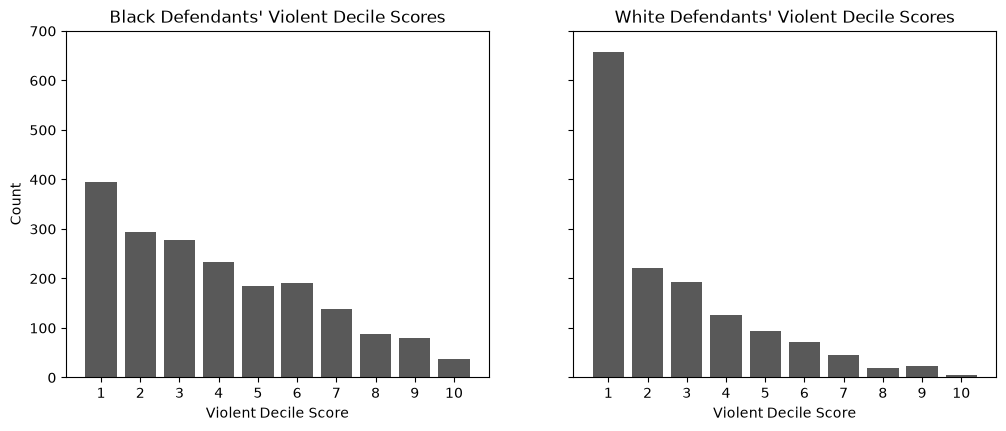

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, (race, label) in zip(axes, [('African-American', 'Black'), ('Caucasian', 'White')]):
    counts = vdf[vdf.race == race].v_decile_score.value_counts().sort_index()
    ax.bar(counts.index.astype(str), counts.values, color='0.35')
    ax.set_ylim(0, 700)
    ax.set_xlabel('Violent Decile Score')
    ax.set_title(f"{label} Defendants' Violent Decile Scores")
axes[0].set_ylabel('Count')
plt.show()

In [24]:
vdf['high_score'] = (vdf.v_score_text != 'Low').astype(int)
vmodel = smf.logit(formula, data=vdf).fit(disp=0)
print(vmodel.summary())

                           Logit Regression Results                           
Dep. Variable:             high_score   No. Observations:                 4020
Model:                          Logit   Df Residuals:                     4008
Method:                           MLE   Df Model:                           11
Date:                Thu, 22 Oct 2026   Pseudo R-squ.:                  0.3662
Time:                        22:01:37   Log-Likelihood:                -1499.4
converged:                       True   LL-Null:                       -2365.9
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                                          coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------------------------
Intercept                                              -2.2427      0.113    -19.802      0.000      -2.465      -2.021
C(sex, T

In [25]:
v_black_rr = relative_risk(vmodel, "C(race, Treatment('Caucasian'))[T.African-American]")
v_young_rr = relative_risk(vmodel, "C(age_cat, Treatment('25 - 45'))[T.Less than 25]")
print(f"Black vs. white:          {v_black_rr:.3f}")
print(f"Under 25 vs. age 25-45:   {v_young_rr:.3f}")

Black vs. white:          1.774
Under 25 vs. age 25-45:   7.414


### ✍️ Your turn — Question 5

Summarize the violent-score regression.

> For the violent score, Black defendants are ____% more likely than white defendants to get a higher score, controlling for the same factors.
>
> Defendants under 25 are ____ times as likely to get a higher score as middle-aged defendants.

Is the racial gap larger or smaller than for the general recidivism score?

**Your answer (Q5):**

For the violent score, Black defendants are approximately **77.4% more likely** than white defendants to receive a higher score (**RR = 1.774**), controlling for the same modeled factors. Defendants under 25 are **7.414 times** as likely to receive a higher score as defendants aged 25–45. The adjusted racial gap is **larger** than for the general score: about **77.4% versus 45.3%**. These are the notebook helper's reference-profile relative-risk estimates.

## 💭 Reflection 2: Racial bias in scores

The regressions "control for" prior record, charge degree, age, sex, and actual two-year recidivism.

* In your own words, what does it mean that the race effect remains *after* controlling for these things?
* COMPAS does **not** use race as an input. How could the scores still differ by race? (Think about the questionnaire items described in the article.)
* What can this regression **not** tell us? Name at least one limitation.

**Your reflection (R2):**

The remaining race association means that differences in the measured predictors do not fully account for the score gap in this fitted model. It compares defendants with the same modeled age category, sex, prior count, charge degree, and recorded two-year outcome, rather than simply comparing the two groups' averages. The article describes questions about parental incarceration, friends' drug use, and school fights, which could reflect unequal social conditions ([Machine Bias](https://www.propublica.org/article/machine-bias-risk-assessments-in-criminal-sentencing)). Such variables could act as proxies for race even if the questionnaire never asks for race directly. The regression cannot establish intentional discrimination or identify which proprietary scoring rule causes the difference. Unmeasured factors, imperfect records, and the model's assumptions could also affect the estimates. I therefore read this as evidence of an adjusted disparity that deserves investigation, rather than proof of one specific causal mechanism.

## Predictive Accuracy of COMPAS

To test whether COMPAS does an accurate job of sorting people into Low, Medium and High risk, ProPublica ran a **Cox proportional hazards model**. Northpointe, the company that created COMPAS, also ran a Cox model in its [validation study](http://cjb.sagepub.com/content/36/1/21.abstract).

A Cox model compares how quickly different groups "fail" (here, reoffend). A **hazard ratio** of 2 means a group reoffends at twice the rate of the reference group (here, Low scorers) at any given time. The **concordance** measures how well the scores *rank* people: 0.5 is a coin flip and 1.0 is perfect.

The data has one row per period a person spent outside jail, and people are removed from the "at risk" pool while they are incarcerated. Due to errors in the underlying jail data, we filter out a small number of rows whose end date is not after the start date.

In [26]:
def load_cox_data(path):
    """Loads a parsed COMPAS file and prepares it for survival analysis.

    Drops rows without a valid score or with an end date that is not after the start date,
    and adds categorical race and score columns with the reference levels used by ProPublica.

    Args:
        path: Path to 'cox-parsed.csv' or 'cox-violent-parsed.csv'.

    Returns:
        pd.DataFrame: One row per at-risk interval, with added 'race_factor' (reference
        Caucasian) and 'score_factor' (reference Low) columns.
    """
    data = pd.read_csv(path)
    data = data[(data.score_text != 'N/A') & data.score_text.notna() & (data.end > data.start)].copy()
    races = ['Caucasian', 'African-American', 'Asian', 'Hispanic', 'Native American', 'Other']
    data['race_factor'] = pd.Categorical(data.race, categories=races)       # reference = Caucasian
    data['score_factor'] = pd.Categorical(data.score_text, categories=['Low', 'Medium', 'High'])  # reference = Low
    return data

data = load_cox_data('./cox-parsed.csv')
grp = data.drop_duplicates('id')
len(grp)

10314

In [27]:
grp.score_factor.value_counts()

score_factor
Low       5751
Medium    2611
High      1952
Name: count, dtype: int64

In [28]:
grp.race_factor.value_counts()

race_factor
African-American    5147
Caucasian           3569
Hispanic             944
Other                571
Asian                 51
Native American       32
Name: count, dtype: int64

In [29]:
cox_score = fit_cox(data, 'score_factor')

n = 13344, number of events = 3469

                           coef  exp(coef)  se(coef)    p
covariate                                                
score_factor[T.Medium]  0.79627    2.21725   0.04077  0.0
score_factor[T.High]    1.24969    3.48927   0.04146  0.0



Concordance = 0.636


In [30]:
cox_decile = fit_cox(data, 'decile_score')

n = 13344, number of events = 3469

                 coef  exp(coef)  se(coef)    p
covariate                                      
decile_score  0.19493    1.21523    0.0058  0.0



Concordance = 0.664


### ✍️ Your turn — Question 6

Interpret the two models above.

> People placed in the **High** category are ____ times as likely to recidivate as people in the Low category.
>
> The concordance of the Low/Medium/High categories is ____%, which is **(higher / lower)** than the 68% reported in Northpointe's validation study. The 1–10 decile score has a concordance of ____%.

*Hint:* the hazard ratio is in the `exp(coef)` column.

**Your answer (Q6):**

People in the **High** category have approximately **3.489 times** the recidivism hazard of people in the Low category (**exp(coef) = 3.48927**). The Low/Medium/High categories have concordance **63.6%**, which is **lower** than the 68% stated for Northpointe's validation study; the 1–10 decile score has concordance **66.4%**. The hazard ratio compares instantaneous event rates among people still at risk, rather than directly multiplying their two-year probabilities. Concordance measures the ordering of comparable pairs, not the percentage of individual defendants correctly classified.

We can test whether the algorithm behaves differently across races by including a **race × score interaction** in the Cox model.

In [31]:
cox_interaction = fit_cox(data, 'race_factor * score_factor')

n = 13344, number of events = 3469

                                                           coef  exp(coef)  se(coef)        p
covariate                                                                                    
race_factor[T.African-American]                         0.27879    1.32154   0.06080  0.00000
race_factor[T.Asian]                                   -0.77694    0.45981   0.50200  0.12170
race_factor[T.Hispanic]                                -0.06352    0.93846   0.09673  0.51142
race_factor[T.Native American]                         -1.25468    0.28517   1.00100  0.21005
race_factor[T.Other]                                    0.01419    1.01429   0.11049  0.89779
score_factor[T.Medium]                                  0.84286    2.32301   0.07142  0.00000
score_factor[T.High]                                    1.28350    3.60927   0.08357  0.00000
race_factor[T.African-American]:score_factor[T.Medium] -0.17261    0.84147   0.09097  0.05778
race_factor[T.Asian]:sco


Concordance = 0.646


In [32]:
params = cox_interaction.params_
high = params['score_factor[T.High]']
medium = params['score_factor[T.Medium]']
black_high = params['race_factor[T.African-American]:score_factor[T.High]']
black_medium = params['race_factor[T.African-American]:score_factor[T.Medium]']

print(f"Black High Hazard:   {math.exp(high + black_high):.2f}")
print(f"White High Hazard:   {math.exp(high):.2f}")
print(f"Black Medium Hazard: {math.exp(medium + black_medium):.2f}")
print(f"White Medium Hazard: {math.exp(medium):.2f}")

Black High Hazard:   2.99
White High Hazard:   3.61
Black Medium Hazard: 1.95
White Medium Hazard: 2.32


### ✍️ Your turn — Question 7

Each hazard above compares High (or Medium) scorers to **Low scorers of the same race**.

> High-risk white defendants are ____ times as likely to recidivate as low-risk white defendants, while high-risk Black defendants are ____ times as likely as low-risk Black defendants.

What does it mean that the "High" label separates people *less* sharply for Black defendants? How does this connect to the logistic regression results?

**Your answer (Q7):**

High-risk white defendants have **3.61 times** the recidivism hazard of low-risk white defendants, while high-risk Black defendants have **2.99 times** the hazard of low-risk Black defendants. The smaller within-race ratio means that High and Low labels separate observed hazards less sharply for Black defendants in this fitted model. Together with the logistic regression's **45.3%** adjusted increase in higher-score assignment, this raises concern that higher labels do not carry the same degree of separation for both groups. However, the general-score Black × High interaction has **p = 0.05738**, so this particular difference is not statistically significant at the 0.05 level and should not be treated as conclusive on its own.

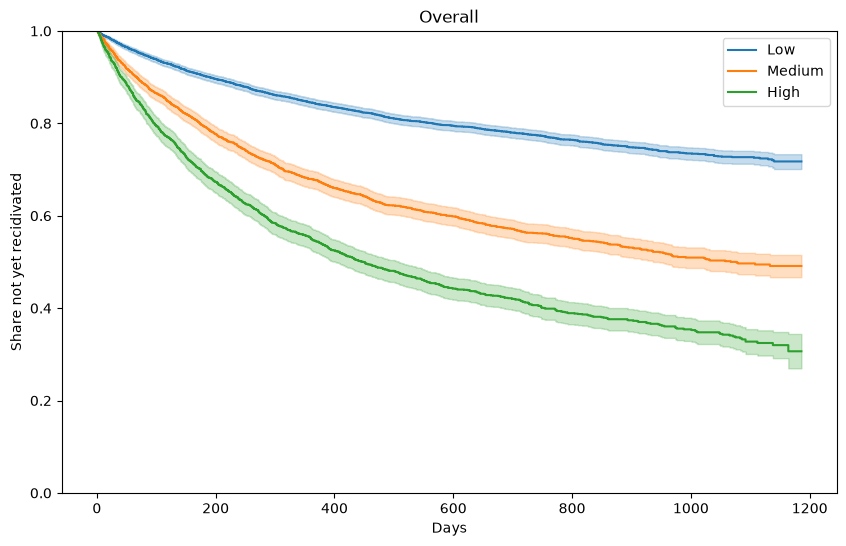

In [33]:
fig, ax = plt.subplots(figsize=(10, 6))
km_by_score(data, ax, 'Overall')
plt.show()

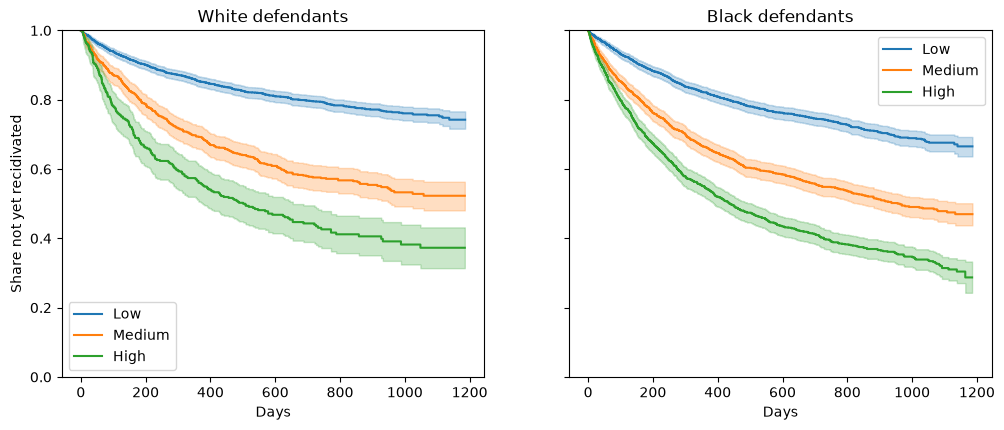

In [34]:
white = data[data.race == 'Caucasian']
black = data[data.race == 'African-American']

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
km_by_score(white, axes[0], 'White defendants')
km_by_score(black, axes[1], 'Black defendants')
plt.show()

In [35]:
pd.DataFrame({'Overall': survival_at(data),
              'Black': survival_at(black),
              'White': survival_at(white)})

,Overall,Black,White
Low,0.776,0.743,0.795
Medium,0.563,0.548,0.576
High,0.408,0.398,0.435


### ✍️ Your turn — Question 8

These **Kaplan-Meier** curves show the share of people who have *not* yet reoffended over time. The table gives that share at two years (730 days).

> According to these race-specific plots, Black defendants **(do / do not)** recidivate at higher rates than white defendants. For example, ____% of Black Low-risk defendants had not reoffended after two years, compared to ____% of white Low-risk defendants.

*Hint:* recidivism rate = 1 − survival.

**Your answer (Q8):**

Black defendants **do** have higher estimated recidivism rates within each score category in these race-specific results, although the differences are modest. After two years, **74.3%** of Black Low-risk defendants had not reoffended, compared with **79.5%** of white Low-risk defendants. The corresponding estimated recidivism rates are **25.7%** and **20.5%**, a **5.2 percentage-point** difference. For Medium and High scores, Black survival is also lower (**54.8% vs. 57.6%** and **39.8% vs. 43.5%**). These are descriptive estimates for recorded recidivism in this sample, not evidence that race causes offending.

In [36]:
print('White defendants')
_ = fit_cox(white, 'score_factor')
print('\n\nBlack defendants')
_ = fit_cox(black, 'score_factor')

White defendants


n = 4564, number of events = 1023

                           coef  exp(coef)  se(coef)    p
covariate                                                
score_factor[T.Medium]  0.83965    2.31556   0.07144  0.0
score_factor[T.High]    1.27628    3.58327   0.08365  0.0

Concordance = 0.625


Black defendants


n = 6862, number of events = 2035

                           coef  exp(coef)  se(coef)    p
covariate                                                
score_factor[T.Medium]  0.67026    1.95474   0.05636  0.0
score_factor[T.High]    1.09514    2.98959   0.05475  0.0

Concordance = 0.623


### ✍️ Your turn — Question 9

> When fit separately for each race, the concordance is ____ for white defendants and ____ for Black defendants. These values are **(very similar / very different)**.

Does this mean COMPAS is equally fair to both groups? Why or why not?

**Your answer (Q9):**

When fitted separately, concordance is **0.625 for white defendants** and **0.623 for Black defendants**. These values are **very similar**. Similar ranking performance does not establish equal fairness: a decision threshold can still create different false-positive and false-negative rates, and the same label can correspond to different observed risks. The later truth tables show exactly why ranking accuracy alone is insufficient.

### Violent recidivism

In [37]:
violent_data = load_cox_data('./cox-violent-parsed.csv')
vgrp = violent_data.drop_duplicates('id')
print(len(vgrp))
cox_violent = fit_cox(violent_data, 'score_factor')

10985


n = 18178, number of events = 818

                           coef  exp(coef)  se(coef)    p
covariate                                                
score_factor[T.Medium]  0.80350    2.23334   0.08699  0.0
score_factor[T.High]    1.38311    3.98729   0.08410  0.0

Concordance = 0.651


In [38]:
cox_violent_interaction = fit_cox(violent_data, 'race_factor + race_factor * score_factor')

n = 18178, number of events = 818

                                                            coef     exp(coef)   se(coef)        p
covariate                                                                                         
race_factor[T.African-American]                          0.19764  1.218520e+00    0.13206  0.13449
race_factor[T.Asian]                                    -0.58385  5.577500e-01    1.00458  0.56112
race_factor[T.Hispanic]                                 -0.17537  8.391500e-01    0.21497  0.41462
race_factor[T.Native American]                         -12.77686  0.000000e+00  665.41477  0.98468
race_factor[T.Other]                                    -0.04459  9.563900e-01    0.24326  0.85455
score_factor[T.Medium]                                   0.62920  1.876110e+00    0.15827  0.00007
score_factor[T.High]                                     1.25019  3.490990e+00    0.17200  0.00000
race_factor[T.African-American]:score_factor[T.Medium]   0.12972  1.138510


Concordance = 0.663


In [39]:
print('Black defendants')
_ = fit_cox(violent_data[violent_data.race == 'African-American'], 'score_factor')
print('\n\nWhite defendants')
_ = fit_cox(violent_data[violent_data.race == 'Caucasian'], 'score_factor')

Black defendants


n = 9712, number of events = 495

                           coef  exp(coef)  se(coef)    p
covariate                                                
score_factor[T.Medium]  0.75890    2.13592   0.12018  0.0
score_factor[T.High]    1.24115    3.45959   0.11396  0.0

Concordance = 0.638


White defendants


n = 6041, number of events = 221

                           coef  exp(coef)  se(coef)        p
covariate                                                    
score_factor[T.Medium]  0.63097    1.87943   0.15828  0.00007
score_factor[T.High]    1.25016    3.49089   0.17202  0.00000

Concordance = 0.610


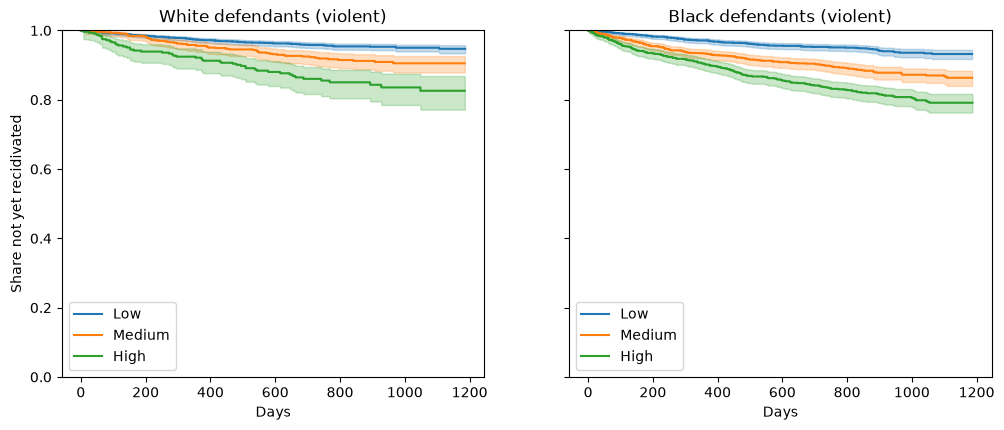

In [40]:
vwhite = violent_data[violent_data.race == 'Caucasian']
vblack = violent_data[violent_data.race == 'African-American']

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
km_by_score(vwhite, axes[0], 'White defendants (violent)')
km_by_score(vblack, axes[1], 'Black defendants (violent)')
plt.show()

### ✍️ Your turn — Question 10

> COMPAS's violent recidivism score has an overall concordance of ____%, which is **(slightly higher / slightly lower)** than the general score.
>
> In the interaction model, the coefficient for Black defendants with High violent scores (`race_factor[T.African-American]:score_factor[T.High]`) **(is / is not)** statistically significant (p = ____).

What does that p-value mean for whether the violent score behaves differently by race in this model?

**Your answer (Q10):**

The violent recidivism score has overall concordance **65.1%**, which is **slightly higher** than the general categorical score's **63.6%**. The Black × High violent-score interaction **is not statistically significant**, with **p = 0.97051**. Assuming a zero interaction and the model's assumptions, a result at least this extreme would be very unsurprising. This provides no evidence here that the High-versus-Low hazard ratio differs between Black and white defendants, but it does not prove equivalence, identical absolute risks, or equal error rates. Some very small racial groups also have large standard errors in this model, which limits broad conclusions from the full interaction fit.

## 💭 Reflection 3: Predictive accuracy

COMPAS correctly ranks pairs of defendants about 64% of the time (a coin flip would get 50%).

* Is that "good enough" to inform decisions about bail, sentencing, or parole? Explain your reasoning.
* Who should decide what level of accuracy is acceptable: the company, judges, legislators, or the public?
* The article contrasts ProPublica's 63.6% with Northpointe's 68%. Why might two analyses of the same tool get different numbers?

**Your reflection (R3):**

A concordance of 63.6% shows some predictive information, but I would not consider it enough by itself to justify restricting someone's freedom. It describes how often comparable pairs are ranked correctly, so it does not tell a judge whether one particular person will commit another offense. I would require evidence about calibration, error rates, uncertainty, and performance against simpler alternatives before allowing the score to influence a decision. The acceptable standard should be set through public oversight involving legislators, judges, affected communities, and independent researchers, rather than being chosen by the vendor alone. The 63.6% and 68% results could differ because the studies use different populations, follow-up rules, outcome definitions, or data-cleaning choices. Even changing from categories to deciles in this notebook raises concordance from 63.6% to 66.4%, showing that the representation of the score matters. For me, the central question is whether any predictive benefit is large enough to justify the errors and how those errors are distributed.

## Directions of the Racial Bias

The analysis above shows that COMPAS treats Black and white defendants differently, but we haven't yet looked at the **direction** of its mistakes. A risk tool can make two kinds of errors:

|                     | Labeled Low | Labeled Medium/High |
|---------------------|-------------|---------------------|
| **Did not reoffend** | ✅ True negative | ❌ **False positive** |
| **Reoffended**       | ❌ **False negative** | ✅ True positive |

* **False positive rate** = of the people who did *not* reoffend, the share labeled higher risk.
* **False negative rate** = of the people who *did* reoffend, the share labeled low risk.

This part of the analysis uses ProPublica's original Python helper file, `truth_tables.py`.

In [41]:
people = []
with open('./cox-parsed.csv') as f:
    reader = PeekyReader(DictReader(f))
    try:
        while True:
            p = Person(reader)
            if p.valid:
                people.append(p)
    except StopIteration:
        pass

pop = list(filter(lambda i: ((i.recidivist == True and i.lifetime <= 730) or
                              i.lifetime > 730), list(filter(lambda x: x.score_valid, people))))
recid = list(filter(lambda i: i.recidivist == True and i.lifetime <= 730, pop))
rset = set(recid)
surv = [i for i in pop if i not in rset]

In [42]:
print('All defendants')
table(list(recid), list(surv))

All defendants
           	Low	High
Survived   	2681	1282	0.55
Recidivated	1216	2035	0.45
Total: 7214.00
False positive rate: 32.35
False negative rate: 37.40
Specificity: 0.68
Sensitivity: 0.63
Prevalence: 0.45
PPV: 0.61
NPV: 0.69
LR+: 1.94
LR-: 0.55


In [43]:
print(f"Total pop: {len(pop)}")
lifetimes = [i.lifetime for i in pop]
print(f"Average followup time {statistics.mean(lifetimes):.2f} (sd {statistics.stdev(lifetimes):.2f})")
print(f"Median followup time {statistics.median(lifetimes)}")

Total pop: 7214
Average followup time 622.87 (sd 392.19)
Median followup time 766.0


In [44]:
print('Black defendants')
is_afam = is_race('African-American')
table(list(filter(is_afam, recid)), list(filter(is_afam, surv)))

Black defendants
           	Low	High
Survived   	990	805	0.49
Recidivated	532	1369	0.51
Total: 3696.00
False positive rate: 44.85
False negative rate: 27.99
Specificity: 0.55
Sensitivity: 0.72
Prevalence: 0.51
PPV: 0.63
NPV: 0.65
LR+: 1.61
LR-: 0.51


In [45]:
print('White defendants')
is_white = is_race('Caucasian')
table(list(filter(is_white, recid)), list(filter(is_white, surv)))

White defendants
           	Low	High
Survived   	1139	349	0.61
Recidivated	461	505	0.39
Total: 2454.00
False positive rate: 23.45
False negative rate: 47.72
Specificity: 0.77
Sensitivity: 0.52
Prevalence: 0.39
PPV: 0.59
NPV: 0.71
LR+: 2.23
LR-: 0.62


In [46]:
black_fpr, black_fnr = error_rates(list(filter(is_afam, recid)), list(filter(is_afam, surv)))
white_fpr, white_fnr = error_rates(list(filter(is_white, recid)), list(filter(is_white, surv)))

print(f"False positive rate  Black: {black_fpr:.2f}%   White: {white_fpr:.2f}%   ratio: {black_fpr / white_fpr:.2f}")
print(f"False negative rate  Black: {black_fnr:.2f}%   White: {white_fnr:.2f}%   ratio: {white_fnr / black_fnr:.2f}")

False positive rate  Black: 44.85%   White: 23.45%   ratio: 1.91
False negative rate  Black: 27.99%   White: 47.72%   ratio: 1.71


### ✍️ Your turn — Question 11

Use the three truth tables and the summary cell above.

> Overall, the false positive rate is ____%. That number is **(higher / lower)** for Black defendants at ____% and **(higher / lower)** for white defendants at ____%.
>
> This means that under COMPAS, Black defendants are ____% more likely than white defendants to get a higher score and **not** go on to commit more crimes within two years.
>
> In the other direction, COMPAS misclassifies white reoffenders as low risk ____% more often than Black reoffenders.

*Hint:* a ratio of 1.5 means "50% more likely."

**Your answer (Q11):**

Overall, the false-positive rate is **32.35%**. It is **higher** for Black defendants at **44.85%** and **lower** for white defendants at **23.45%**.

Among defendants with **no recorded recidivism within two years**, Black defendants are approximately **91.2% more likely** to receive a Medium/High label: **[((805/1795) / (349/1488)) − 1] × 100 ≈ 91.2%**. In the other direction, COMPAS labels white recidivists Low risk approximately **70.5% more often** than Black recidivists: **[((461/966) / (532/1901)) − 1] × 100 ≈ 70.5%**, using false-negative rates of **47.72% versus 27.99%**. These are relative differences in conditional error rates, not percentage-point differences or proof of whether someone actually committed an unrecorded crime.

What if only the **High** category counts as "high risk" (and Medium is grouped with Low)?

In [47]:
print('White defendants (High only)')
hightable(list(filter(is_white, recid)), list(filter(is_white, surv)))

White defendants (High only)
           	Low	High
Survived   	1407	81	0.61
Recidivated	771	195	0.39
Total: 2454.00
False positive rate: 5.44
False negative rate: 79.81
Specificity: 0.95
Sensitivity: 0.20
Prevalence: 0.39
PPV: 0.71
NPV: 0.65
LR+: 3.71
LR-: 0.84


In [48]:
print('Black defendants (High only)')
hightable(list(filter(is_afam, recid)), list(filter(is_afam, surv)))

Black defendants (High only)
           	Low	High
Survived   	1511	284	0.49
Recidivated	1160	741	0.51
Total: 3696.00
False positive rate: 15.82
False negative rate: 61.02
Specificity: 0.84
Sensitivity: 0.39
Prevalence: 0.51
PPV: 0.72
NPV: 0.57
LR+: 2.46
LR-: 0.72


### ✍️ Your turn — Question 12

> When only the **High** category counts as high risk, the false positive rate is ____% for Black defendants and ____% for white defendants.

Does the gap between the groups shrink, grow, or stay about the same in *relative* terms (compute the ratio)? Why might the choice of cut-off matter for a judge?

**Your answer (Q12):**

When only **High** counts as high risk, the false-positive rate is **15.82% for Black defendants** and **5.44% for white defendants**. The ratio is **(284/1795) / (81/1488) ≈ 2.91**, compared with about **1.91** under the Medium/High threshold, so the gap **grows in relative terms**. The absolute gap nevertheless shrinks from about **21.40** to **10.38 percentage points**. A stricter cutoff flags fewer people who do not recidivate, but it also misses more people who do: false-negative rates rise to **61.02% for Black defendants** and **79.81% for white defendants**. A judge's cutoff therefore changes both the burden of unnecessary restrictions and the risk of missed cases.

### Violent recidivism

COMPAS's violent recidivism score has a similar overall accuracy to the general score. Let's build the same truth tables.

In [49]:
vpeople = []
with open('./cox-violent-parsed.csv') as f:
    reader = PeekyReader(DictReader(f))
    try:
        while True:
            p = Person(reader)
            if p.valid:
                vpeople.append(p)
    except StopIteration:
        pass

vpop = list(filter(lambda i: ((i.violent_recidivist == True and i.lifetime <= 730) or
                              i.lifetime > 730), list(filter(lambda x: x.vscore_valid, vpeople))))
vrecid = list(filter(lambda i: i.violent_recidivist == True and i.lifetime <= 730, vpeople))
vrset = set(vrecid)
vsurv = [i for i in vpop if i not in vrset]

In [50]:
print('All defendants')
vtable(list(vrecid), list(vsurv))

All defendants
           	Low	High
Survived   	4121	1597	0.89
Recidivated	347	389	0.11
Total: 6454.00
False positive rate: 27.93
False negative rate: 47.15
Specificity: 0.72
Sensitivity: 0.53
Prevalence: 0.11
PPV: 0.20
NPV: 0.92
LR+: 1.89
LR-: 0.65


In [51]:
print('Black defendants')
vtable(list(filter(is_afam, vrecid)), list(filter(is_afam, vsurv)))

Black defendants
           	Low	High
Survived   	1692	1043	0.86
Recidivated	170	273	0.14
Total: 3178.00
False positive rate: 38.14
False negative rate: 38.37
Specificity: 0.62
Sensitivity: 0.62
Prevalence: 0.14
PPV: 0.21
NPV: 0.91
LR+: 1.62
LR-: 0.62


In [52]:
print('White defendants')
vtable(list(filter(is_white, vrecid)), list(filter(is_white, vsurv)))

White defendants
           	Low	High
Survived   	1679	380	0.91
Recidivated	129	77	0.09
Total: 2265.00
False positive rate: 18.46
False negative rate: 62.62
Specificity: 0.82
Sensitivity: 0.37
Prevalence: 0.09
PPV: 0.17
NPV: 0.93
LR+: 2.03
LR-: 0.77


In [53]:
vblack_fpr, vblack_fnr = error_rates(list(filter(is_afam, vrecid)), list(filter(is_afam, vsurv)), prefix='v')
vwhite_fpr, vwhite_fnr = error_rates(list(filter(is_white, vrecid)), list(filter(is_white, vsurv)), prefix='v')

print(f"False positive rate  Black: {vblack_fpr:.2f}%   White: {vwhite_fpr:.2f}%   ratio: {vblack_fpr / vwhite_fpr:.2f}")
print(f"False negative rate  Black: {vblack_fnr:.2f}%   White: {vwhite_fnr:.2f}%   ratio: {vwhite_fnr / vblack_fnr:.2f}")

False positive rate  Black: 38.14%   White: 18.46%   ratio: 2.07
False negative rate  Black: 38.37%   White: 62.62%   ratio: 1.63


### ✍️ Your turn — Question 13

> For the violent score, Black defendants are about ____ times as likely as white defendants to be false positives (labeled higher risk but did not reoffend violently).
>
> White defendants are ____% more likely than Black defendants to get a lower score and go on to commit another violent crime.

Is the pattern the same as for the general recidivism score?

**Your answer (Q13):**

For the violent score, Black defendants who did not violently recidivate are about **2.07 times** as likely as white defendants in that outcome group to be false positives (**38.14% / 18.46%**). Among recorded violent recidivists, white defendants are approximately **63.2% more likely** to be labeled Low risk: **[((129/206) / (170/443)) − 1] × 100 ≈ 63.2%**, using false-negative rates of **62.62% versus 38.37%**. The direction matches the general score: Black non-recidivists are more often labeled higher risk, while white recidivists are more often labeled Low risk.

## 💭 Reflection 4: Fairness: whose definition?

Northpointe responded to ProPublica by arguing that COMPAS is fair because it is **calibrated**: a given score means roughly the same chance of reoffending regardless of race (you saw this in the Kaplan-Meier curves). ProPublica argues it is unfair because the **error rates** (false positives and false negatives) differ sharply by race.

* Explain each side's definition of fairness in your own words, using numbers from this notebook.
* Black and white defendants in this data reoffend at different overall rates. Researchers have shown that when base rates differ, a tool **cannot** be both calibrated and have equal error rates (unless it is perfect). Which kind of fairness do you think matters more in a courtroom, and why?
* Who bears the cost of a false positive? Who bears the cost of a false negative?

**Your reflection (R4):**

Northpointe's calibration definition asks whether a given score corresponds to roughly the same recorded recidivism probability across racial groups. Our Low-risk estimates are 25.7% for Black defendants and 20.5% for white defendants, so the broad categories are similar but this table does not demonstrate exact calibration. ProPublica's error-rate definition asks whether mistakes fall equally across groups, whereas our false-positive rates are 44.85% versus 23.45% and false-negative rates are 27.99% versus 47.72% for Black and white defendants respectively. The general truth tables also show different overall recorded recidivism rates, about 51.4% for Black defendants and 39.4% for white defendants. When base rates differ, predictive parity and equal false-positive and false-negative rates generally conflict for an imperfect, nondegenerate classifier, so a single accuracy statistic cannot resolve the fairness dispute ([Chouldechova](https://arxiv.org/abs/1610.07524)). In a courtroom, I would prioritize reducing false positives and unjustified racial differences in them, while continuing to report calibration and false negatives. A false positive can cost a defendant freedom, employment, and family stability even when no new offense is recorded. A false negative can leave potential victims and communities exposed to harm and can also mean missing an opportunity to provide useful support.

## Gender Differences in COMPAS Scores

In terms of underlying recidivism rates, we can look at gender-specific Kaplan-Meier estimates.

In [54]:
female = data[data.sex == 'Female']
male = data[data.sex == 'Male']

pd.DataFrame({'Female': survival_at(female), 'Male': survival_at(male)})

,Female,Male
Low,0.838,0.758
Medium,0.659,0.535
High,0.525,0.388


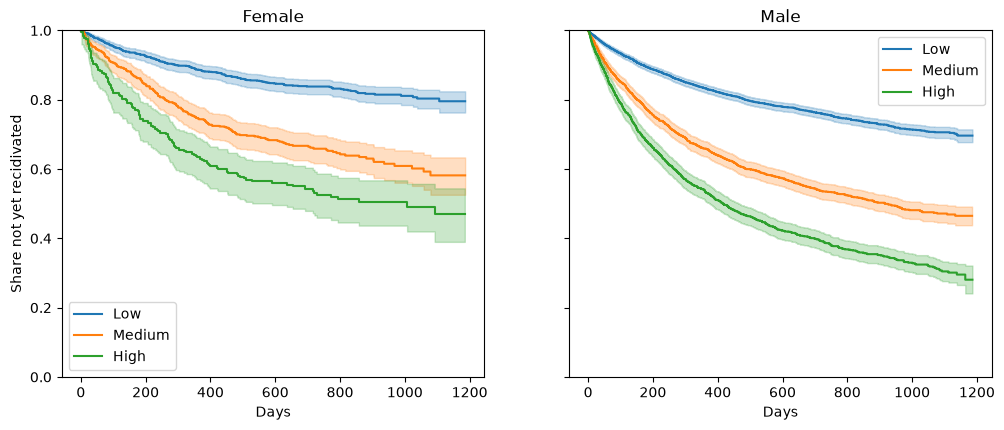

In [55]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
km_by_score(female, axes[0], 'Female')
km_by_score(male, axes[1], 'Male')
plt.show()

### ✍️ Your turn — Question 14

Compare the curves and the two-year survival table.

> There is a **(small / striking)** difference between women and men. A woman labeled **High** risk has a two-year survival of ____%, which is closest to a man labeled ____ risk (____%).
>
> In other words, the COMPAS score treats a High-risk woman the same as a ____-risk man.

**Your answer (Q14):**

There is a **striking** difference between women and men. A woman labeled **High** risk has an estimated two-year survival of **52.5%**, closest to a man labeled **Medium** risk (**53.5%**). In terms of observed outcomes, a High-risk woman therefore resembles a **Medium-risk man**: their estimated two-year recidivism rates are **47.5%** and **46.5%**. The labels themselves remain different; the comparison shows that the same category does not imply the same observed risk across sex groups.

## 💭 Reflection 5: Gender

COMPAS gives women and men with the same score different real-world risks.

* If including sex as an input would make the tool more accurate for women, should it be included? Why or why not?
* Would your answer be the same for race? What is different (or not) about the two cases, legally and ethically?

**Your reflection (R5):**

I would consider including sex only if independent evidence showed that it reduced harmful errors for women and the specific use had a defensible legal basis. The 52.5% survival estimate for High-risk women, compared with 53.5% for Medium-risk men, shows why simply applying the same category label can conceal an important difference. I would prefer using such information to audit and correct overprediction or allocate supportive services, rather than automatically increasing anyone's punishment. I would be more reluctant to use race directly to determine an individual's restrictions because that could turn disparities in recorded policing outcomes into a justification for further unequal treatment. Legally, explicit governmental racial classifications generally face strict scrutiny, while sex classifications generally face intermediate scrutiny; that distinction does not by itself settle whether any particular scoring policy is lawful ([CRS, Equal Protection Background, p. 2](https://www.congress.gov/crs_external_products/LSB/PDF/LSB11329/LSB11329.1.pdf#page=2)). Ethically, both choices require asking whether a group average should influence an individual's treatment and who would bear the resulting errors. For both race and sex, I support retaining group information for transparent fairness audits even when it is excluded from the individual decision rule.

## 💭 Reflection 6: Closing reflection

You have now reproduced the core of ProPublica's analysis yourself.

* Did running the numbers change how you think about the article? What, if anything, surprised you?
* If you were advising Broward County on whether to keep using COMPAS, what would you recommend, and what evidence from this notebook would you point to?

**Your reflection (R6):**

Reproducing the calculations makes the concern about COMPAS more concrete because the same data can support similar ranking performance and very different error burdens. The most striking result is that concordance is almost the same for white and Black defendants, 0.625 and 0.623, while their false-positive rates are 23.45% and 44.85%. The gender comparison also shows how a familiar label can hide different observed outcomes. I would recommend that Broward County suspend using these scores to justify more restrictive bail, sentencing, or parole decisions until an independent evaluation demonstrates a clear benefit and acceptable error burdens. That evaluation should compare simpler alternatives, investigate the effects of charging and data-quality differences, and publish results by race and sex along with uncertainty. Any later use should include an understandable explanation, a way to challenge incorrect data, continuing audits, and an explicit public decision about which kinds of errors are acceptable.

### Sources and assistance

Numerical answers use the saved outputs of the supplied Python notebook and local datasets. The assigned background sources are [Machine Bias](https://www.propublica.org/article/machine-bias-risk-assessments-in-criminal-sentencing) and the [ProPublica methodology](https://www.propublica.org/article/how-we-analyzed-the-compas-recidivism-algorithm); additional references appear beside the claims they support.

**AI assistance:** OpenAI Codex installed the required dependencies in the existing Python environment, executed the supplied analysis, and drafted the numerical explanations and reflection responses. The first-person reflections are AI-assisted drafts for the student to review and revise to match their own views. The supplied analysis code was preserved.